# Homework 3 - Aprendizagem

>Teresa Matos- ist1106009   
>Francisco Morão - ist1106067   
>Grupo 46   

## II. Programming

Consider the parkinsons.csv dataset (available at the course’s webpage), where the goal is
to predict a patient’s score on the Unified Parkinson’s Disease Rating Scale based on various
biomedical measurements.
To answer question 5), average the performance of the models over 10 separate runs. In each
run, use a different 80-20 train-test split by setting a random_state=i, with i=1..10.


5) [2v] Train a Linear Regression model, an MLP Regressor with 2 hidden layers of 10
neurons each and no activation functions, and another MLP Regressor with 2 hidden
layers of 10 neurons each using ReLU activation functions. (Use random_state=0 on the
MLPs, regardless of the run). Plot a boxplot of the test MAE of each model.

/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/lib/python3/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:684: ConvergenceWarning: Stochastic Opti

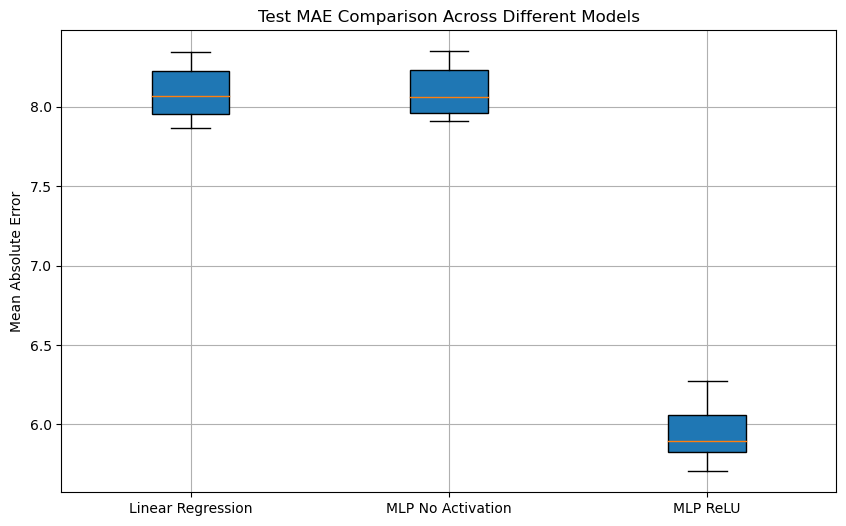

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Load the dataset
data = pd.read_csv('parkinsons.csv')

# Extract features and target from the dataset
X = data.drop(columns=['target'])
y = data['target']

# Prepare to store MAE results for each model
mae_results = {'Linear Regression': [], 'MLP No Activation': [], 'MLP ReLU': []}

# Perform 10 different train-test splits
for i in range(1, 11):
    # Split the data (80% train, 20% test)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=i)

    # Linear Regression Model
    lr_model = LinearRegression()
    lr_model.fit(X_train, y_train)
    lr_predictions = lr_model.predict(X_test)
    lr_mae = mean_absolute_error(y_test, lr_predictions)
    mae_results['Linear Regression'].append(lr_mae)

    # MLP Regressor with no activation functions (identity activation)
    mlp_no_activation = MLPRegressor(hidden_layer_sizes=(10, 10), activation='identity', random_state=0)
    mlp_no_activation.fit(X_train, y_train)
    mlp_no_activation_predictions = mlp_no_activation.predict(X_test)
    mlp_no_activation_mae = mean_absolute_error(y_test, mlp_no_activation_predictions)
    mae_results['MLP No Activation'].append(mlp_no_activation_mae)

    # MLP Regressor with ReLU activation functions
    mlp_relu = MLPRegressor(hidden_layer_sizes=(10, 10), activation='relu', random_state=0, max_iter=1000)
    mlp_relu.fit(X_train, y_train)
    mlp_relu_predictions = mlp_relu.predict(X_test)
    mlp_relu_mae = mean_absolute_error(y_test, mlp_relu_predictions)
    mae_results['MLP ReLU'].append(mlp_relu_mae)

# Plot a boxplot of the test MAE of each model
plt.figure(figsize=(10, 6))
plt.boxplot(mae_results.values(), labels=mae_results.keys(), patch_artist=True)
plt.title('Test MAE Comparison Across Different Models')
plt.ylabel('Mean Absolute Error')
plt.grid()
plt.show()

6) [3v] Compare a Linear Regression with a MLP with no activations, and explain the impact
and the importance of using activation functions in a MLP. Support your reasoning with the
results from the boxplots

The boxplot shows that the Linear Regression and MLP with no activation functions perform similarly in terms of the Mean Absolute Error (MAE), with both models having similar ranges and medians around 8. This outcome is expected because an MLP without activation functions behaves like a linear model. The output of such an MLP is simply a linear combination of the inputs, making it equivalent to linear regression.

However, when we compare these models to the MLP with ReLU activation functions, there is a significant improvement in the MAE. The MLP with ReLU has a lower median and a tighter range of MAE values, indicating better and more consistent performance across different runs. This improvement highlights the importance of using activation functions in neural networks.

Impact of Activation Functions in an MLP:
Non-linearity Introduction: Activation functions like ReLU introduce non-linearity into the model, allowing the neural network to learn and represent more complex patterns in the data that linear models cannot capture.
Capability to Model Complex Relationships: By introducing non-linearities, an MLP with activation functions can approximate complex, non-linear relationships in the data. This ability leads to better predictive performance, as seen in the lower MAE for the MLP with ReLU activation.
ReLU's Benefits: The ReLU activation function helps address issues like vanishing gradients, making it easier to train deeper networks, and it encourages sparse activation, which can improve generalization.
Conclusion:
The results demonstrate that using activation functions in an MLP is crucial for achieving superior performance, especially when modeling complex data relationships. Without activation functions, the network's capacity to learn is limited to linear transformations, akin to linear regression.

7) [4v] Using a 80-20 train-test split with random_state=0, use a Grid Search to tune the
hyperparameters of an MLP regressor with two hidden layers (size 10 each). The
parameters to search over are: (i) L2 penalty, with the values {0.0001, 0.001, 0.01}; (ii)
learning rate, with the values {0.001, 0.01, 0.1}; and (iii) batch size, with the values
{32, 64, 128}. Plot the test MAE for each combination of hyperparameters, report the
best combination, and discuss the trade-offs between the combinations.


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import GridSearchCV
Xtrain, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

mlp = MLPRegressor(hidden_layer_sizes=(10, 10), max_iter=2000, random_state=0)

param_grid = {
    'alpha': [0.0001, 0.001, 0.01],
    'learning_rate_init': [0.001, 0.01, 0.1], 
    'batch_size': [32, 64, 128]
}

grid_search = GridSearchCV(mlp, param_grid, scoring='neg_mean_absolute_error', cv=5, n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

results_df = pd.DataFrame(grid_search.cv_results)

resultsdf['mean_test_mae'] = -results_df['mean_test_score']

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

alphas = results_df['param_alpha'].astype(float)
learning_rates = results_df['param_learning_rate_init'].astype(float)
batch_sizes = results_df['param_batch_size'].astype(float)
maes = results_df['mean_test_mae'].astype(float)

scatter = ax.scatter(batch_sizes, alphas,learning_rates, c=maes, cmap='viridis', s=100)

ax.set_xlabel('Batch Size')
ax.set_ylabel('L2 Penalty (alpha)')
ax.set_zlabel('Learning Rate')
ax.set_title('3D Hyperparameter Grid Search: MLP Regressor Test MAE')

cbar = fig.colorbar(scatter, ax=ax, pad=0.1)
cbar.set_label('Test MAE')

plt.show()

best_params = grid_search.best_params
print(f"Best Hyperparameters: {bestparams}")
y_pred = grid_search.best_estimator.predict(X_test)
test_mae = mean_absolute_error(y_test, y_pred)
print(f"Test MAE with Best Hyperparameters: {test_mae:.4f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits


AttributeError: 'GridSearchCV' object has no attribute 'cv_results'

Explanation:
Grid Search Setup: The GridSearchCV searches over the specified hyperparameter combinations using 5-fold cross-validation.
Scoring Metric: We use negative MAE (neg_mean_absolute_error) for scoring in Grid Search. The negative sign is used because Grid Search minimizes the metric by default.
Result Plotting: We plot the test MAE for each combination of hyperparameters to visualize how they affect the performance.
Best Hyperparameters: The script prints the best combination and the corresponding test MAE.
Discussion Points:
L2 Penalty (alpha): Controls the regularization strength. Higher values may reduce overfitting but can also increase bias.
Learning Rate: Determines how quickly the model adapts to the problem. Smaller values can lead to slow convergence, while larger values may cause overshooting.
Batch Size: Smaller batch sizes offer more noise and can help the model generalize better, while larger batch sizes may speed up training.
The results will show the trade-offs between these parameters.